# Recurrent location extraction: experiments and findings

This notebook records two stages: the original equal-token GRU experiments, followed by the matched-row comparison of word/BPE tokenization and BiGRU/BiLSTM. The latest comparison and conclusions are in the final section. All extraction models start from random weights and use BIO tags. The frozen three-fold experiment pool excludes final local evaluation and competition texts.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
PROJECT=Path.cwd()
if PROJECT.name=='notebooks': PROJECT=PROJECT.parent.parent
elif PROJECT.name=='eda': PROJECT=PROJECT.parent
HERE=PROJECT/'eda'
OUTPUT=HERE/'output'
role=json.loads((OUTPUT/'role_summary_v2.json').read_text())
folds=json.loads((OUTPUT/'cv_summary_v1.json').read_text())
bundle=json.loads((OUTPUT/'extractor_bundle_v1.json').read_text())
benchmark=json.loads((OUTPUT/'eda_benchmark.json').read_text())
assert role['group_overlap']==role['document_overlap']==role['text_overlap']==0
assert folds['group_overlap']==folds['document_overlap']==folds['exact_text_overlap']==0
assert bundle['counts']['cv']==folds['sampled_rows']
display(pd.DataFrame(folds['counts'],columns=folds['columns']))
print('Hardware:',benchmark['gpu'],'| bundle SHA256:',bundle['sha256'][:16])

,source,fold,rows,positive_rows,groups,documents
0,ru,0,10652,3250,863,1035
1,ru,1,10652,3251,862,1023
2,ru,2,10652,3251,862,1049
3,uk,0,10477,2440,10442,0
4,uk,1,10478,2440,10444,0
5,uk,2,10477,2440,10444,0


Hardware: Tesla T4 | bundle SHA256: 83f07b11cab50b36


The CV subset has 63,388 rows. Folds contain about 10,500 Ukrainian and 10,650 Russian rows each, with positive-row counts balanced to within one per source. Duplicate-connected groups and Russian documents never cross folds. The Colab timing run used a Tesla T4. The initial timing estimate covered only training steps; actual pilot durations below include tokenization, prediction, and checkpoint saving.

,model,source,precision,recall,string_f1,span_f1,seconds,training_windows
0,bpe_mixed,uk,0.521,0.577,0.548,0.539,19.961,11151
1,bpe_mixed,ru,0.613,0.653,0.632,0.623,19.961,11151
2,bpe_mixed,combined,0.573,0.621,0.596,0.588,19.961,11151
3,bpe_uk,uk,0.502,0.671,0.574,0.562,19.698,11825
4,bpe_uk,ru,0.104,0.215,0.140,0.138,19.698,11825
5,bpe_uk,combined,0.231,0.407,0.295,0.289,19.698,11825
6,word_mixed,uk,0.717,0.577,0.640,0.636,21.266,15852
7,word_mixed,ru,0.867,0.681,0.763,0.759,21.266,15852
8,word_mixed,combined,0.803,0.637,0.711,0.707,21.266,15852


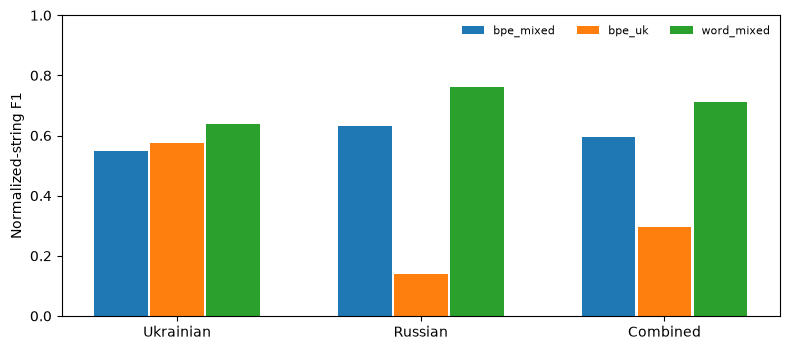

In [2]:
pilot=json.loads((OUTPUT/'eda_pilot_results.json').read_text())
pilot_summary=json.loads((OUTPUT/'eda_pilot_summary.json').read_text())
assert pilot['bundle_sha256']==bundle['sha256']
rows=[]
for item in pilot['results']:
    for source in ('uk','ru','combined'):
        metrics=item['metrics'][source]
        rows.append(dict(model=item['name'].removeprefix('pilot_pilot_'),source=source,
                         precision=metrics['string_precision'],recall=metrics['string_recall'],
                         string_f1=metrics['string_f1'],span_f1=metrics['span_f1'],
                         seconds=item['total_seconds'],training_windows=item['training']['training_windows']))
pilot_table=pd.DataFrame(rows)
display(pilot_table.round(3))
fig,ax=plt.subplots(figsize=(8,3.6))
for i,(model,subset) in enumerate(pilot_table.groupby('model',sort=False)):
    ax.bar([j+i*.23 for j in range(3)],subset.set_index('source').loc[['uk','ru','combined'],'string_f1'],width=.22,label=model)
ax.set_xticks([.23,1.23,2.23],['Ukrainian','Russian','Combined'])
ax.set_ylabel('Normalized-string F1')
ax.set_ylim(0,1)
ax.legend(frameon=False,ncol=3,fontsize=8)
plt.tight_layout()
plt.show()

The word-token mixed pilot scores 0.711 combined F1, ahead of BPE mixed at 0.596. Ukrainian-only BPE reaches 0.574 on Ukrainian but only 0.140 on Russian. At the equal token budget, word tokenization also exposes the model to more sentences (15,852 versus 11,151 for mixed BPE). That is part of the training tradeoff; it prevents attributing the gap solely to token identity. These are one-seed pilot results, not final model rankings. The three frozen CV folds test consistency.

In [3]:
sensitivity=json.loads((OUTPUT/'eda_pilot_score_sensitivity.json').read_text())
display(pd.DataFrame([{'model':key.split(':')[0],'corrected_punctuation_f1':value['f1']}
                      for key,value in sensitivity['score'].items() if key.endswith(':combined')]))

,model,corrected_punctuation_f1
0,bpe_mixed,0.600945
1,bpe_uk,0.300490
2,word_mixed,0.717421


The published scorer's punctuation expression appears to be literal rather than interpolated. Correcting that expression as a sensitivity check changes combined pilot F1 by about 0.005–0.007 and preserves the ranking. This is not verification of the live Kaggle scorer. A focused error review found missed lists of places, merged neighboring names, and raw labels with malformed boundaries; examples were selected for errors and cannot estimate prevalence.

In [4]:
import json
import pandas as pd
from IPython.display import display
from pathlib import Path
root=HERE
profile=pd.DataFrame(json.loads((root/"output/pilot_error_profile.json").read_text())["profile"])
display(profile[["model","source","negative_rows","negative_with_prediction","positive_rows","positive_with_no_prediction","positive_with_overlapping_wrong_span"]])

,model,source,negative_rows,negative_with_prediction,positive_rows,positive_with_no_prediction,positive_with_overlapping_wrong_span
0,bpe_mixed,uk,773,69,227,41,53
1,bpe_mixed,ru,680,59,320,45,68
2,bpe_uk,uk,773,89,227,15,57
3,bpe_uk,ru,680,286,320,87,82
4,word_mixed,uk,773,32,227,56,25
5,word_mixed,ru,680,15,320,73,15


The word model has fewer spurious predictions on negative rows than the mixed BPE model, while leaving more positive rows entirely without a prediction. This supports examining precision–recall tradeoffs during full training. Rows with overlapping but nonmatching spans include both model boundary errors and defective gold offsets; the categories overlap and are descriptive.

## Frozen three-fold comparison

The same outer evaluation rows are used for all three candidates. Each fold fits its tokenizer on the other two folds only. Training uses a fixed epoch count and decoder; no outer-fold predictions choose checkpoints or thresholds. Fold scores and pooled out-of-fold metrics are reported separately by source. Bootstrap intervals resample document/duplicate groups and do not capture retraining variability.

In [5]:
import json
import pandas as pd
from pathlib import Path
from IPython.display import display
out=HERE/"output"
cv=json.loads((out/"eda_cv_summary.json").read_text())
assert cv["mode"]=="cv"
records=[]
for model,results in cv["source_results"].items():
    for source in ("uk","ru","combined"):
        records.append(dict(model=model,source=source,
            pooled_string_f1=results[source]["string"]["f1"],
            pooled_span_f1=results[source]["span"]["f1"],
            fold_scores=results["fold_scores"][source]))
display(pd.DataFrame(records).round(3))
display(pd.DataFrame(cv["paired_group_bootstrap"]).T)

,model,source,pooled_string_f1,pooled_span_f1,fold_scores
0,bpe_mixed,uk,0.536,0.529,"[0.526182, 0.540863, 0.54024]"
1,bpe_mixed,ru,0.576,0.570,"[0.585536, 0.590205, 0.552667]"
2,bpe_mixed,combined,0.559,0.552,"[0.559838, 0.568856, 0.54727]"
3,bpe_uk,uk,0.600,0.593,"[0.581201, 0.620398, 0.601447]"
4,bpe_uk,ru,0.127,0.125,"[0.114446, 0.153602, 0.121599]"
5,bpe_uk,combined,0.306,0.303,"[0.273127, 0.353802, 0.306117]"
6,word_mixed,uk,0.616,0.613,"[0.635389, 0.576259, 0.644804]"
7,word_mixed,ru,0.685,0.682,"[0.723192, 0.644134, 0.696791]"
8,word_mixed,combined,0.655,0.652,"[0.685247, 0.614676, 0.674195]"


,observed,bootstrap_percentile_95,independent_groups
bpe_mixed_minus_bpe_uk:uk,-0.06456,"[-0.072401, -0.057058]",31330
bpe_mixed_minus_bpe_uk:ru,0.449372,"[0.436367, 0.462559]",2587
bpe_mixed_minus_bpe_uk:combined,0.252165,"[0.240706, 0.26592]",33917
bpe_mixed_minus_word_mixed:uk,-0.079888,"[-0.089238, -0.071683]",31330
bpe_mixed_minus_word_mixed:ru,-0.108434,"[-0.118957, -0.098013]",2587
bpe_mixed_minus_word_mixed:combined,-0.096041,"[-0.103169, -0.088737]",33917


The mixed word model leads in all three folds and both source slices. Combined pooled normalized-string F1 is 0.655, versus 0.559 for mixed BPE and 0.306 for Ukrainian-only BPE. The word-versus-mixed-BPE advantage is 0.096, with a paired group-bootstrap interval of 0.089–0.103. The bootstrap conditions on the fitted models and does not include retraining variation. Ukrainian-only BPE improves the Ukrainian slice over mixed BPE but scores 0.127 on Russian, so source composition remains a material decision.

## Name exposure and text length

The rows below separate labeled location strings that appeared in examples actually consumed by a model, appeared only in the remaining training-fold pool, or never appeared in that pool. The tokenizer still saw all text in the training-fold pool. Recall is computed over normalized gold strings; it does not measure false positives.

In [6]:
exposure=json.loads((out/'eda_cv_exposure.json').read_text())
records=[]
for result in exposure['results']:
    model=result['model'].split('_',2)[-1]
    for item in result['source_results']:
        records.append({'model':model,**item})
name_table=pd.DataFrame(records).groupby(['model','source','exposure'],as_index=False)[['gold','correct']].sum()
name_table['recall']=(name_table['correct']/name_table['gold']).round(3)
display(name_table[['model','source','exposure','gold','recall']])
length_rows=pd.DataFrame(json.loads((out/'eda_cv_slices.json').read_text())['results'])
display(length_rows[(length_rows.model=='word_mixed') & (length_rows.slice_kind=='length')][['source','slice','rows','f1']].round(3))

,model,source,exposure,gold,recall
0,bpe_mixed,ru,absent_from_fold_training,3590,0.299
1,bpe_mixed,ru,available_unsampled,1689,0.405
2,bpe_mixed,ru,supervised_seen,9090,0.788
3,bpe_mixed,uk,absent_from_fold_training,3001,0.251
4,bpe_mixed,uk,available_unsampled,1128,0.371
5,bpe_mixed,uk,supervised_seen,6611,0.782
6,bpe_uk,ru,absent_from_fold_training,3590,0.071
7,bpe_uk,ru,available_unsampled,10779,0.195
8,bpe_uk,uk,absent_from_fold_training,3001,0.263
9,bpe_uk,uk,available_unsampled,491,0.373


,source,slice,rows,f1
33,ru,100-199,15946,0.682
34,ru,200+,3037,0.677
35,ru,50-99,10854,0.700
36,ru,<50,2119,0.677
41,uk,100-199,12104,0.620
42,uk,200+,1521,0.608
43,uk,50-99,15091,0.613
44,uk,<50,2716,0.602


The mixed word model recovers 83.3% of Ukrainian and 86.3% of Russian labeled strings seen in its selected training examples. Recall drops to 27.2% and 35.2% for strings absent from the full training fold. It still leads mixed BPE on that absent-name slice. This suggests that rare-name generalization deserves attention, while leaving the cause open: word and BPE models saw different numbers of supervised rows. Source rows of 200 or more characters remain much shorter than many competition posts, so the length table does not settle post-level performance.

In [7]:
qualitative=json.loads((out/"eda_qualitative.json").read_text())
assert len(qualitative["rows"])==26
mismatches=[r for r in qualitative["rows"] if r["actual_strings"]!=r["predicted_strings"]]
print("Rows with different normalized sets:",len(mismatches),"of 26")
display(pd.DataFrame([{"row_id":r["row_id"],"text_excerpt":r["text"][:140],
                       "labeled":r["actual_strings"],"predicted":r["predicted_strings"]}
                      for r in mismatches[:6]]))

Rows with different normalized sets: 17 of 26


,row_id,text_excerpt,labeled,predicted
0,1,"Проспект Бандери стоїть, як і пів міста… довго...",[проспект бандери],[]
1,2,☢️Радіаційний фон (мкР/год) по Київщині станом...,"[баришівка, бориспіль, біла церква, київ, київ...","[київ, київщині]"
2,3,"Друзі. Останні дві ночі, і ще декілька наступн...",[проспекті івасюка],[]
3,5,Подовження роботи закладів харчування\n\nВладо...,[києву],"[києва, україни, україні]"
4,7,ДТП біля заїзду в ТЦ Аркадія\n\n📍Індустріальни...,[тц аркадія],[]
5,9,В результате массированной атаки врага ночью в...,"[бучанском, фастовском]",[фастовском]


This fixed 26-item labeled sample in `labeling_sample.csv` is qualitative. The selected pilot word model differs from labels on 17 rows, often missing lists of places, streets, and neighborhoods or extracting extra names from long posts. The sample was not used for tuning. It reveals a domain risk that source-corpus CV cannot measure: strong source F1 does not guarantee performance on multi-line competition posts. The matched-row experiments below test whether the earlier word advantage persists with equal example exposure and a second recurrent encoder.

## Matched-row recurrent comparison

This follow-up gives word and BPE models the same training rows within each fold. It compares BiGRU and BiLSTM at the same hidden width and three-epoch pilot budget. The fixed Ukrainian-only word BiGRU checks the language-mixture effect. Scores are normalized location-string micro-F1; exact-span F1 and grouped paired intervals provide boundary and uncertainty checks. The earlier equal-token comparison remains separate because it used different row counts.

Each fit uses three epochs, batch size 32, AdamW (learning rate 0.003, weight decay 0.01), 96-dimensional random embeddings, one bidirectional recurrent layer with 96 units per direction, dropout 0.15, and weighted BIO loss (O/B/I: 1/3/2). The seed is 3012026. All 15 fits ran on a Colab T4. Tokenizers learn up to 16,000 entries from all text in the two training folds, while supervised training consumes only the saved smaller row selection. The Ukrainian-only control shares this mixed-language vocabulary. No checkpoint selection or threshold tuning uses held-out predictions.


In [8]:
comparison_dir = OUTPUT / 'eda_comparison'
comparison = json.loads((comparison_dir / 'summary.json').read_text())
selection = json.loads((comparison_dir / 'selection.json').read_text())
representation = json.loads((comparison_dir / 'representation.json').read_text())
rows = []
for name, item in comparison['candidates'].items():
    for source in ('uk', 'ru', 'combined'):
        rows.append({'configuration': name, 'source': source,
                     'string_precision': item['scores'][source]['string']['precision'],
                     'string_recall': item['scores'][source]['string']['recall'],
                     'string_f1': item['scores'][source]['string']['f1'],
                     'exact_span_f1': item['scores'][source]['span']['f1']})
display(pd.DataFrame(rows).round(3))
pairs = []
for name, sources in comparison['pairs'].items():
    for source, item in sources.items():
        pairs.append({'comparison': name, 'source': source,
                      'F1_difference': item['difference'],
                      'group_bootstrap_95': item['group_bootstrap_95']})
display(pd.DataFrame(pairs).round(3))

,configuration,source,string_precision,string_recall,string_f1,exact_span_f1
0,mixed_gru_word,uk,0.567,0.596,0.581,0.579
1,mixed_gru_word,ru,0.663,0.665,0.664,0.662
2,mixed_gru_word,combined,0.621,0.635,0.628,0.626
3,mixed_gru_bpe,uk,0.464,0.574,0.513,0.503
4,mixed_gru_bpe,ru,0.537,0.620,0.576,0.566
5,mixed_gru_bpe,combined,0.505,0.600,0.548,0.538
6,mixed_lstm_word,uk,0.592,0.609,0.600,0.599
7,mixed_lstm_word,ru,0.685,0.677,0.681,0.678
8,mixed_lstm_word,combined,0.644,0.648,0.646,0.644
9,mixed_lstm_bpe,uk,0.460,0.595,0.519,0.512


,comparison,source,F1_difference,group_bootstrap_95
0,mixed_gru_word_minus_mixed_gru_bpe,uk,0.068,"[0.058798, 0.078045]"
1,mixed_gru_word_minus_mixed_gru_bpe,ru,0.089,"[0.079196, 0.09922]"
2,mixed_gru_word_minus_mixed_gru_bpe,combined,0.080,"[0.073497, 0.086844]"
3,mixed_lstm_word_minus_mixed_lstm_bpe,uk,0.082,"[0.073182, 0.090024]"
4,mixed_lstm_word_minus_mixed_lstm_bpe,ru,0.100,"[0.090698, 0.109122]"
5,mixed_lstm_word_minus_mixed_lstm_bpe,combined,0.093,"[0.085537, 0.099744]"
6,mixed_lstm_word_minus_mixed_gru_word,uk,0.019,"[0.012647, 0.025579]"
7,mixed_lstm_word_minus_mixed_gru_word,ru,0.017,"[0.011308, 0.021862]"
8,mixed_lstm_word_minus_mixed_gru_word,combined,0.018,"[0.01391, 0.02147]"
9,mixed_lstm_bpe_minus_mixed_gru_bpe,uk,0.005,"[-0.001011, 0.011879]"


In [9]:
coverage = pd.DataFrame(representation['results'])
coverage = coverage.groupby(['tokenizer', 'source'], as_index=False)[
    ['gold_mentions', 'mentions_with_unknown_token', 'unrepresentable_mentions',
     'gold_mention_pieces']].sum()
coverage['unknown_mention_share'] = coverage['mentions_with_unknown_token'] / coverage['gold_mentions']
coverage['unrepresentable_mention_share'] = coverage['unrepresentable_mentions'] / coverage['gold_mentions']
coverage['pieces_per_mention'] = coverage['gold_mention_pieces'] / coverage['gold_mentions']
display(coverage[['tokenizer', 'source', 'gold_mentions', 'unknown_mention_share',
                  'unrepresentable_mention_share', 'pieces_per_mention']].round(3))

,tokenizer,source,gold_mentions,unknown_mention_share,unrepresentable_mention_share,pieces_per_mention
0,bpe,ru,14504,0.000,0.001,2.272
1,bpe,uk,10827,0.000,0.005,2.250
2,word,ru,14504,0.398,0.004,1.244
3,word,uk,10827,0.409,0.006,1.249


In [10]:
errors = json.loads((comparison_dir / 'error_analysis.json').read_text())
sensitivity = json.loads((comparison_dir / 'score_sensitivity.json').read_text())
training = []
for candidate, item in comparison['candidates'].items():
    training.append({'configuration': candidate,
                     'rows_per_fold': [run['training_rows'] for run in item['training']],
                     'tokens_per_fold': [run['training_tokens'] for run in item['training']],
                     'parameters': item['training'][0]['parameters']})
display(pd.DataFrame(training))
exposure = pd.DataFrame(errors['exposure'])
display(exposure[exposure['candidate'].isin(['mixed_gru_word', 'mixed_gru_bpe',
                                                'mixed_lstm_word'])][
    ['candidate', 'source', 'exposure', 'gold', 'recall']].round(3))
negative = pd.DataFrame(errors['slices'])
display(negative[(negative['slice_kind'] == 'locations') &
                 (negative['slice'] == '0') &
                 (negative['candidate'].isin(['mixed_gru_word', 'mixed_gru_bpe',
                                              'mixed_lstm_word']))][
    ['candidate', 'source', 'rows', 'false_positives_per_1000_rows']].round(1))
display(pd.DataFrame([{'candidate': name,
                       'literal_f1': item['scores']['combined']['string']['f1'],
                       'corrected_punctuation_f1': sensitivity['scores'][name + ':combined']['f1']}
                      for name, item in comparison['candidates'].items()]).round(3))

,configuration,rows_per_fold,tokens_per_fold,parameters
0,mixed_gru_word,"[10586, 10586, 10574]","[200823, 200869, 201237]",1648323
1,mixed_gru_bpe,"[10586, 10586, 10574]","[285774, 286298, 285578]",1648323
2,mixed_lstm_word,"[10586, 10586, 10574]","[200823, 200869, 201237]",1685571
3,mixed_lstm_bpe,"[10586, 10586, 10574]","[285774, 286298, 285578]",1685571
4,uk_gru_word,"[10586, 10586, 10574]","[189385, 190050, 189529]",1648323


,candidate,source,exposure,gold,recall
0,mixed_gru_bpe,ru,absent_from_fold_training,3590,0.305
1,mixed_gru_bpe,ru,available_unsampled,1700,0.372
2,mixed_gru_bpe,ru,supervised,9079,0.790
3,mixed_gru_bpe,uk,absent_from_fold_training,3001,0.252
4,mixed_gru_bpe,uk,available_unsampled,1225,0.377
5,mixed_gru_bpe,uk,supervised,6514,0.760
6,mixed_gru_word,ru,absent_from_fold_training,3590,0.343
7,mixed_gru_word,ru,available_unsampled,1700,0.345
8,mixed_gru_word,ru,supervised,9079,0.852
9,mixed_gru_word,uk,absent_from_fold_training,3001,0.246


,candidate,source,rows,false_positives_per_1000_rows
5,mixed_gru_bpe,ru,22204,127.5
13,mixed_gru_bpe,uk,24112,123.3
21,mixed_gru_word,ru,22204,102.7
29,mixed_gru_word,uk,24112,108.2
53,mixed_lstm_word,ru,22204,94.1
61,mixed_lstm_word,uk,24112,99.7


,candidate,literal_f1,corrected_punctuation_f1
0,mixed_gru_word,0.628,0.634
1,mixed_gru_bpe,0.548,0.554
2,mixed_lstm_word,0.646,0.650
3,mixed_lstm_bpe,0.553,0.559
4,uk_gru_word,0.324,0.327


## What the bounded comparison establishes

With equal training rows, word tokens remain ahead of BPE on both sources and all three folds. Pooled F1 is 0.628 for word BiGRU versus 0.548 for BPE BiGRU; word BiLSTM scores 0.646 versus 0.553 for BPE BiLSTM. The word advantage therefore does not depend entirely on seeing more examples in the earlier equal-token experiment. It is smaller for GRU than the earlier 0.096 pooled gap, but the training samples also changed, so the difference between experiments is not a causal estimate of exposure.

Word BiLSTM exceeds word BiGRU by 0.018 pooled F1, with positive differences in each fold and both languages. LSTM has more parameters at the same hidden width, and each configuration has one training seed. This is a promising stage 2 candidate, not an architecture verdict. BPE LSTM's 0.005 gain over BPE GRU is much less clear. The corrected punctuation diagnostic raises every score by about 0.002–0.006 without changing the ranking; live Kaggle scoring remains unverified.

Ukrainian-only word BiGRU improves Ukrainian F1 from 0.581 to 0.631, while Russian F1 falls from 0.664 to 0.165. The matched-row substitution also changes which Ukrainian names are supervised and the total token count, so the precise cause of the Ukrainian gain is not isolated. The pooled score sums correct, extra, and missed strings across both sources. It does not give the two language F1 scores equal weight, and the competition language mix is different.

The word models recover more supervised names and generate fewer extra predictions, especially on rows with multiple labeled locations. On names absent from the fold's training pool, Ukrainian recall remains around 0.24–0.25 for the three leading mixed-language models examined in this slice. BPE's complete token coverage has not solved the rare-name problem. Manual review found BPE fragments such as `Ста` and `Чер` predicted as locations, shared misses on place lists, and at least one apparently unlabeled location (`Румынии`). These examples show both model errors and possible annotation omissions; they are not rate estimates. Long competition-style posts remain poorly represented by the source folds.